# Browsing Behaviour and Online Purchases
## An Analysis Using Statistical Tests and Machine Learning
**Andrin Manav Ramroop | ST10108675 | RPDA8412**

This study asks whether recorded browsing behaviour helps explain differences between purchasing and non-purchasing sessions and supports purchase classification. The notebook connects the research questions to the actual computations, figures and conclusions. Think of it as the working behind the answer, with the calculator showing its receipts.

Each row represents a historical website session. The outcome, Revenue, records whether that session ended in a purchase. The dataset's title mentions intention, but the observed outcome is a transaction indicator. A visitor's motivation, later purchases and reasons for leaving remain outside these records (Sakar and Kastro, 2018).

| Research question | What we examine | Evidence produced |
|---|---|---|
| RQ1 How do browsing patterns differ by outcome? | Counts, durations and exit-related measures | Summaries and Figures 1–2 |
| RQ2 Which measures are statistically associated with purchases? | Eight numerical measures and visitor type | Nine adjusted tests and effect sizes |
| RQ3 How well do the models identify purchasing sessions? | Three classifiers on the same holdout | Ranking scores, error counts and Figures 3–6 |
| RQ4 What recommendations follow? | Results, uncertainty and feature timing | Sensitivity checks and final interpretation |

Run the notebook from top to bottom. The data-loading cell accepts the supplied CSV. The code also writes copies of its numerical evidence and figures into an outputs folder. The saved outputs in this notebook allow a reader to inspect the analysis without running it again.

## 1 Preparing the analysis environment
Python uses specialist libraries much as a workshop uses different tools. NumPy handles numerical arrays, pandas organises tables, SciPy performs statistical tests, scikit-learn fits and evaluates models, and Matplotlib draws the figures.

The installation cell requests the versions used to reproduce the report. The next cell prints the versions actually loaded into memory. These can differ if Colab already imported a package before installation. Restarting the session after installation allows the requested versions to load. The displayed versions are the record of what actually ran.

A seed of 42 controls reproducible random choices. The number has no special statistical powers. It simply gives the computer the same starting instructions. Package versions and data order also matter, so a seed alone is an incomplete reproduction record.

**Why this takes a while.** The six searches contain 220 training-fold fits plus six final refits. Each forest fit grows 500 trees. Colab is doing a small forestry project while we wait. The remaining checks add 1,000 bootstrap resamples and 20 shuffles for each input.

**Software attribution.** The imported libraries are credited as computer programs in the reference list. The NumPy entry identifies the version recorded in your saved run. Matplotlib's version is the one specified by the installation cell because its loaded version was not printed. The reproduction note at the end distinguishes the requested environment from the actual recorded environment (Matplotlib development team, n.d.; NumPy developers, n.d.; SciPy developers, n.d.-c; Scikit-learn developers, n.d.-f; The pandas development team, n.d.-b).

In [ ]:
# Install once in a new environment. Restart the kernel if required.
%pip install -q numpy==2.3.5 pandas==2.2.3 scipy==1.17.0 scikit-learn==1.8.0 matplotlib==3.10.8

In [ ]:
import sys, json, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
OUT = Path("outputs")
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "sklearn": sklearn.__version__,
}
display(pd.Series(versions, name="Execution environment"))
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=300, bbox_inches="tight")
    plt.show()


,Execution environment
python,3.13.18
numpy,2.4.6
pandas,2.2.3
scipy,1.17.0
sklearn,1.8.0


## 2 Loading the dataset and checking its identity
The code first looks for online_shoppers_intention.csv in the data folder or beside the notebook. In Colab, it asks for an upload if the file is absent. Once loaded, the table is called df. In ordinary language, df is our spreadsheet for the rest of the analysis.

The CSV contains 12,330 sessions and 18 columns, including the outcome. The checks confirm its dimensions, true/false outcome types, missing values and numerical validity. An assert statement stops execution when an expected condition fails. It is the notebook's bouncer checking the guest list before the analysis enters.

The SHA-256 value is a fingerprint of the file's exact bytes. Matching it establishes that the same archived CSV was used. It cannot establish that the original records are accurate or representative. Those questions require knowledge of how the data were collected.

Kaggle distributes the dataset as version 1, while UCI documents the original source. The supplied CSV is unchanged from the archived project file. Original dataset credit belongs to Sakar and Kastro (2018), with distribution credit to Patel (2021). UCI supplies the CC BY 4.0 licence.

**Reading the audit.** Duplicate rows are counted and retained for the main analysis. Identical-looking sessions can arise for different people. The grouped split below handles repeated predictor profiles, and the later deduplication check examines whether repeated rows materially affect the result.

In [ ]:
paths = [
    Path("data/online_shoppers_intention.csv"),
    Path("online_shoppers_intention.csv"),
]
csv_path = next((p for p in paths if p.exists()), None)
if csv_path is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Place the supplied CSV inside data/ and rerun.")
    print("Upload the supplied online_shoppers_intention.csv")
    uploaded = files.upload()
    csv_path = next(
        (Path(p) for p in uploaded if Path(p).name == "online_shoppers_intention.csv"),
        None,
    )
    if csv_path is None:
        raise FileNotFoundError("Required CSV was not uploaded.")
raw = csv_path.read_bytes()
checksum = hashlib.sha256(raw).hexdigest()
assert checksum == "b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9"
df = pd.read_csv(csv_path)
assert df.shape == (12330, 18)
assert df.Revenue.dtype == bool and df.Weekend.dtype == bool
assert df.isna().sum().sum() == 0
assert np.isfinite(df.select_dtypes("number")).all().all()
assert (df.select_dtypes("number") >= 0).all().all()
print("SHA-256:", checksum)
print("Shape:", df.shape, "| Complete duplicate rows:", df.duplicated().sum())
display(df.head())


SHA-256: b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9
Shape: (12330, 18) | Complete duplicate rows: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3 Dividing records fairly between development and testing
A model needs examples to learn from and separate examples on which we assess it. Development records support fitting and selecting settings. The held-out test records provide the final comparison. Letting the model practise on its test records would be rather like handing out the marking memo before the exam.

**What counts as a group?** The code selects 16 predictors, excluding Revenue and PageValues, and hashes their values. Rows with identical predictor profiles receive the same group identifier. Setting index=False prevents a spreadsheet-style row number from changing that identifier. An additional check compares the number of hashes with the number of distinct profiles (The pandas development team, n.d.-a).

StratifiedGroupKFold keeps each group in one partition while trying to preserve the purchase proportions. The first of five splits supplies the test set. Five further folds within development compare model settings. The balance is approximate because whole groups must travel together (Scikit-learn developers, n.d.-g).

The code saves row-level assignments and checks for group overlap. Both feature scenarios use these assignments. Adding PageValues therefore changes the available input information while keeping the evaluation records consistent.

**Reading the output.** The report's split contains 9,864 development sessions and 2,466 test sessions, including 381 test purchases. The main statistical tests later describe the full dataset. Their results do not determine which predictors enter the model.

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

six = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
]
cat = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend",
]
other = ["BounceRates", "ExitRates", "SpecialDay"]
browse = six + ["BounceRates", "ExitRates"]
primary = [c for c in df.columns if c not in ["Revenue", "PageValues"]]
y = df.Revenue.astype(int)
groups = pd.util.hash_pandas_object(df[primary], index=False).to_numpy()
assert len(np.unique(groups)) == len(df[primary].drop_duplicates())
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(df[primary], y, groups))
dev, test = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
gdev, gtest = groups[train_idx], groups[test_idx]
assert not set(gdev).intersection(gtest)
folds = list(splitter.split(dev[primary], dev.Revenue.astype(int), gdev))
assert all(not set(gdev[a]).intersection(gdev[b]) for a, b in folds)
pd.DataFrame(
    {
        "source_row": np.arange(len(df)),
        "group_id": groups,
        "partition": np.where(
            np.isin(np.arange(len(df)), test_idx), "test", "development"
        ),
    }
).to_csv(OUT / "partition_assignments.csv", index=False)
fold_assignment = np.full(len(dev), -1)
for fold, (_, valid) in enumerate(folds):
    fold_assignment[valid] = fold
pd.DataFrame({"source_row": dev.index, "development_fold": fold_assignment}).to_csv(
    OUT / "development_folds.csv", index=False
)
display(
    pd.DataFrame(
        {
            "sessions": [len(dev), len(test)],
            "purchases": [dev.Revenue.sum(), test.Revenue.sum()],
            "purchase_proportion": [dev.Revenue.mean(), test.Revenue.mean()],
        },
        index=["Development", "Test"],
    )
)
print("Unique primary profiles:", len(np.unique(groups)))


,sessions,purchases,purchase_proportion
Development,9864,1527,0.154805
Test,2466,381,0.154501


Unique primary profiles: 12205


## 4 RQ1 Exploring browsing patterns
Before fitting a model, I examine what is in the dataset. Figure 1 shows 10,422 non-purchasing sessions and 1,908 purchasing sessions. Purchasers account for about 15.5%. A classifier could therefore predict no purchase for everyone and achieve roughly 84.5% accuracy. That would be an impressive-looking score for a model whose entire business plan is saying no.

The numerical summary describes the development records using the mean, standard deviation, median and quartiles. The median is the middle value, while the quartiles show the middle half of the observations. These help describe browsing measures with long upper tails. Category tables show session counts and purchase proportions for visitor type, month and weekend status.

**How to read Figure 2.** Each curve gives the proportion of a group at or below a browsing value. If the purchaser curve is farther right, purchasers tend to have larger values. The symmetric logarithmic scale accommodates zero values and compresses the long tail. It changes the display scale while leaving the underlying observations intact.

The curves overlap. Product activity and exit-related patterns can therefore carry information while individual sessions remain difficult to classify. These development summaries describe the patterns behind RQ1. Matplotlib produces the figures and pandas produces the tabulations (Matplotlib development team, n.d.; The pandas development team, n.d.-b).

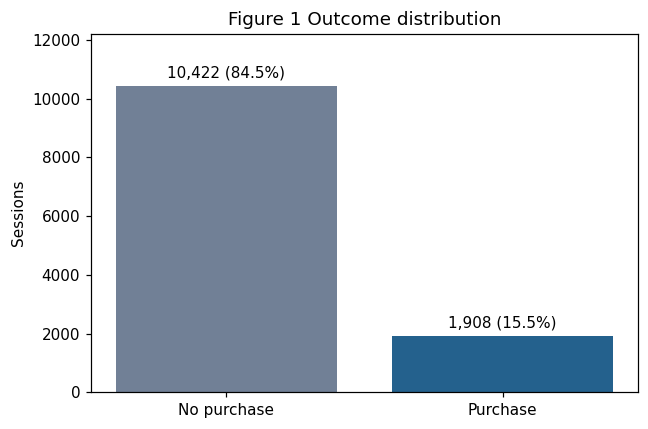

,count,mean,std,min,25%,50%,75%,max
Administrative,9864.0,2.305150,3.342667,0.0,0.000000,1.000000,4.000000,27.00000
Administrative_Duration,9864.0,80.045756,175.234110,0.0,0.000000,7.000000,91.687500,3398.75000
Informational,9864.0,0.506590,1.277702,0.0,0.000000,0.000000,0.000000,24.00000
Informational_Duration,9864.0,34.411656,141.749275,0.0,0.000000,0.000000,0.000000,2549.37500
ProductRelated,9864.0,31.750811,44.773214,0.0,7.000000,18.000000,38.000000,705.00000
ProductRelated_Duration,9864.0,1197.357453,1954.107519,0.0,183.273809,595.775000,1449.152083,63973.52223
BounceRates,9864.0,0.022388,0.048608,0.0,0.000000,0.003175,0.017161,0.20000
ExitRates,9864.0,0.043322,0.048817,0.0,0.014286,0.025517,0.050000,0.20000
SpecialDay,9864.0,0.062064,0.200102,0.0,0.000000,0.000000,0.000000,1.00000


,sessions,purchases,purchase_proportion
VisitorType,,,
New_Visitor,1342,330,0.245902
Other,75,14,0.186667
Returning_Visitor,8447,1183,0.140050


,sessions,purchases,purchase_proportion
Month,,,
Aug,336,65,0.193452
Dec,1369,172,0.125639
Feb,151,2,0.013245
Jul,346,55,0.158960
June,244,24,0.098361
Mar,1555,156,0.100322
May,2662,302,0.113449
Nov,2411,593,0.245956
Oct,440,94,0.213636


,sessions,purchases,purchase_proportion
Weekend,,,
False,7580,1126,0.148549
True,2284,401,0.175569


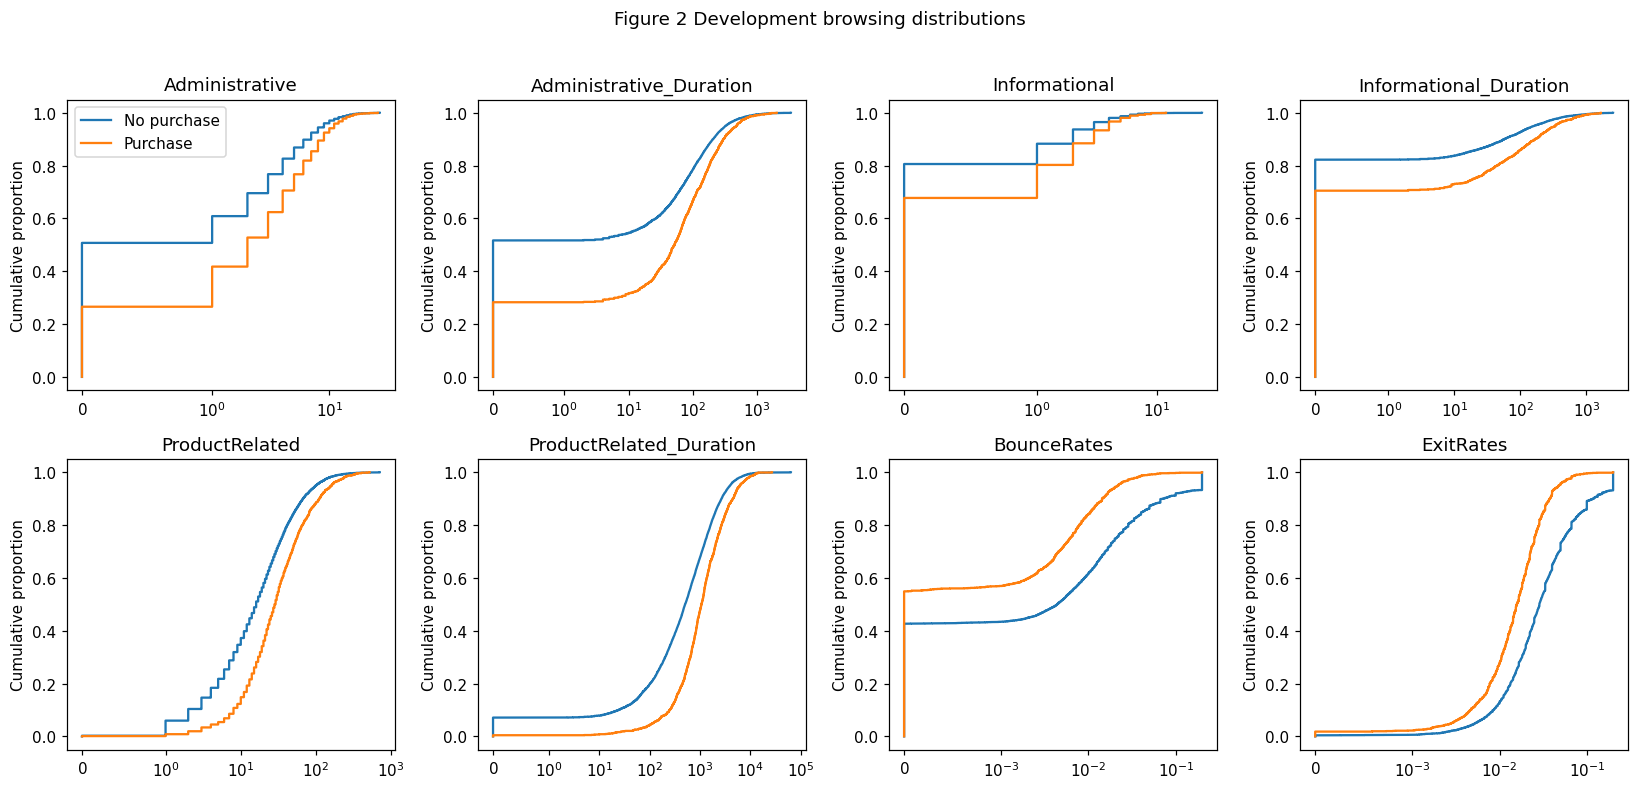

In [ ]:
counts = df.Revenue.value_counts().reindex([False, True])
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["No purchase", "Purchase"], counts, color=["#718096", "#24618d"])
ax.bar_label(bars, labels=[f"{n:,} ({n/len(df):.1%})" for n in counts], padding=4)
ax.set(
    ylabel="Sessions",
    title="Figure 1 Outcome distribution",
    ylim=(0, counts.max() * 1.17),
)
save_figure(fig, "figure_1_outcomes.png")
summary = dev[browse + ["SpecialDay"]].describe().T
summary.to_csv(OUT / "development_numerical_summary.csv")
display(summary)
for col in ["VisitorType", "Month", "Weekend"]:
    table = dev.groupby(col, observed=True).Revenue.agg(
        sessions="size", purchases="sum", purchase_proportion="mean"
    )
    display(table)
    table.to_csv(OUT / f"development_{col}.csv")
dev[browse].corr(method="spearman").to_csv(OUT / "development_spearman.csv")
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, browse):
    for outcome, label in [(False, "No purchase"), (True, "Purchase")]:
        values = np.sort(dev.loc[dev.Revenue == outcome, col].to_numpy())
        ax.step(
            values, np.arange(1, len(values) + 1) / len(values), where="post", label=label
        )
    ax.set_xscale("symlog", linthresh=0.001 if "Rates" in col else 1)
    ax.set(title=col, ylabel="Cumulative proportion")
axes.flat[0].legend()
fig.suptitle("Figure 2 Development browsing distributions", y=1.02)
save_figure(fig, "figure_2_browsing_distributions.png")


## 5 RQ2 Testing associations and reporting their size
The research question concerns whether the selected browsing measures are related to purchase completion. The hypotheses make that question testable.

- For each of the eight numerical measures, H0 states that the distribution is the same in purchasing and non-purchasing sessions. H1 states that the distributions differ.
- For visitor type, H0 states independence from purchase outcome. H1 states an association.

**Numerical comparisons.** The two-sided Mann–Whitney U test compares ranks. It is suitable here for examining distributional differences without assuming normal distributions. The code specifies the asymptotic method and continuity correction. This implementation accounts for tied ranks. A median-only interpretation would need additional assumptions about distribution shape (SciPy developers, n.d.-b).

Purchaser-first U divided by the product of the two group sizes estimates probability of superiority. Ties receive half weight. A value of 0.673 means that a randomly selected purchaser has a larger product-duration value than a randomly selected non-purchaser about 67.3% of the time under that convention. It is a comparison of browsing values.

**Visitor type.** Pearson's chi-square test compares observed category counts with counts expected under independence. Cramér's V describes association strength. The code checks the smallest expected count and contains a permutation alternative for sparse tables (SciPy developers, n.d.-a).

**Why adjust nine tests?** Repeated testing increases the opportunity for a chance finding. Holm's procedure sorts the p-values, applies successively smaller multipliers and enforces monotonic adjusted values. It acts like a supervisor who refuses to be impressed just because we asked the same broad question nine different ways (Holm, 1979).

**Code attribution.** SciPy implements the two test statistics. The surrounding group summaries, superiority calculation and Holm loop are project-specific code implementing the stated methods. Statistical significance, effect size and practical usefulness are interpreted together. The tests treat sessions as observations under independence assumptions. Keeping matching profiles together during model evaluation does not itself establish independence for the full-release statistical tests.

In [ ]:
from scipy.stats import mannwhitneyu, chi2_contingency
from sklearn.base import clone
from sklearn.metrics import confusion_matrix

browse = six + ["BounceRates", "ExitRates"]


def association(data):
    records = []
    for col in browse:
        a = data.loc[data.Revenue, col].dropna()
        b = data.loc[~data.Revenue, col].dropna()
        stat, p = mannwhitneyu(
            a, b, alternative="two-sided", method="asymptotic", use_continuity=True
        )
        records.append(
            {
                "variable": col,
                "purchase_n": len(a),
                "no_purchase_n": len(b),
                "purchase_median": a.median(),
                "purchase_q1": a.quantile(0.25),
                "purchase_q3": a.quantile(0.75),
                "no_purchase_median": b.median(),
                "no_purchase_q1": b.quantile(0.25),
                "no_purchase_q3": b.quantile(0.75),
                "statistic": stat,
                "p_raw": p,
                "probability_purchase_greater_plus_half_ties": stat / (len(a) * len(b)),
            }
        )
    tab = pd.crosstab(data.VisitorType, data.Revenue).reindex(
        columns=[False, True], fill_value=0
    )
    stat, p, dof, expected = chi2_contingency(tab, correction=False)
    if (expected < 5).any():
        rng = np.random.default_rng(42)
        labels = data.Revenue.to_numpy()
        count = 0
        for _ in range(10000):
            ct = pd.crosstab(data.VisitorType, rng.permutation(labels)).reindex(
                index=tab.index, columns=[False, True], fill_value=0
            )
            count += chi2_contingency(ct, correction=False)[0] >= stat - 1e-12
        p = (count + 1) / 10001
        method = "10000 permutations"
    else:
        method = "Pearson chi-square"
    records.append(
        {
            "variable": "VisitorType",
            "statistic": stat,
            "p_raw": p,
            "cramers_v": np.sqrt(
                stat / (len(data) * min(tab.shape[0] - 1, tab.shape[1] - 1))
            ),
            "method": method,
            "min_expected": expected.min(),
        }
    )
    out = pd.DataFrame(records)
    order = np.argsort(out.p_raw.to_numpy())
    ps = out.p_raw.to_numpy()[order]
    adjusted = np.minimum(1, np.maximum.accumulate((len(ps) - np.arange(len(ps))) * ps))
    out["p_holm"] = np.nan
    out.loc[order, "p_holm"] = adjusted
    return out, tab, expected


tests, visitor, expected = association(df)
tests["decision"] = np.where(tests.p_holm < 0.05, "Reject H0", "Do not reject H0")
tests.to_csv(OUT / "association_tests.csv", index=False)
visitor.to_csv(OUT / "visitor_by_outcome.csv")
display(tests)
display(visitor.assign(purchase_proportion=visitor[True] / visitor.sum(axis=1)))
print("Smallest expected count:", expected.min())


,variable,purchase_n,no_purchase_n,purchase_median,purchase_q1,purchase_q3,no_purchase_median,no_purchase_q1,no_purchase_q3,statistic,p_raw,probability_purchase_greater_plus_half_ties,cramers_v,method,min_expected,p_holm,decision
0,Administrative,1908.0,10422.0,2.000000,0.000000,5.000000,0.000000,0.00000,3.000000,1.246404e+07,1.311932e-77,0.626801,NaN,NaN,NaN,7.871590e-77,Reject H0
1,Administrative_Duration,1908.0,10422.0,52.366667,0.000000,151.083333,0.000000,0.00000,83.000000,1.239806e+07,4.672261e-74,0.623483,NaN,NaN,NaN,2.336130e-73,Reject H0
2,Informational,1908.0,10422.0,0.000000,0.000000,1.000000,0.000000,0.00000,0.000000,1.123643e+07,1.202781e-36,0.565066,NaN,NaN,NaN,3.608344e-36,Reject H0
3,Informational_Duration,1908.0,10422.0,0.000000,0.000000,19.000000,0.000000,0.00000,0.000000,1.117353e+07,1.409039e-35,0.561902,NaN,NaN,NaN,2.818077e-35,Reject H0
4,ProductRelated,1908.0,10422.0,29.000000,15.000000,57.000000,16.000000,6.00000,35.000000,1.309305e+07,1.052439e-107,0.658433,NaN,NaN,NaN,7.367070e-107,Reject H0
5,ProductRelated_Duration,1908.0,10422.0,1109.906250,541.906250,2266.011310,510.190000,151.00000,1331.816667,1.338271e+07,5.332268e-128,0.672999,NaN,NaN,NaN,4.265815e-127,Reject H0
6,BounceRates,1908.0,10422.0,0.000000,0.000000,0.006452,0.004255,0.00000,0.020000,7.686683e+06,1.832770e-61,0.386553,NaN,NaN,NaN,7.331080e-61,Reject H0
7,ExitRates,1908.0,10422.0,0.016000,0.009521,0.025000,0.028571,0.01556,0.053846,5.903869e+06,1.156824e-175,0.296898,NaN,NaN,NaN,1.041142e-174,Reject H0
8,VisitorType,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.352519e+02,4.269904e-30,NaN,0.104735,Pearson chi-square,13.153285,4.269904e-30,Reject H0


Revenue,False,True,purchase_proportion
VisitorType,,,
New_Visitor,1272,422,0.249115
Other,69,16,0.188235
Returning_Visitor,9081,1470,0.139323


Smallest expected count: 13.153284671532846


### Interpreting the statistical evidence
All nine adjusted tests reject their null hypotheses at 0.05. Product-related duration has purchaser-first superiority of approximately 0.673, while exit rate has approximately 0.297. These point towards longer product browsing and lower exit rates among purchasers. Visitor-type Cramér's V is approximately 0.105.

A small p-value and a useful business rule are separate questions. The large sample can detect differences even when distributions overlap. The finding gives us a reason to investigate a measure, while the classifier checks how measures work together. Statistical significance has arrived at the meeting. It still needs to explain what it contributes.

## 6 RQ3 Building and comparing three models
The three classifiers offer different ways to combine the available inputs. Logistic regression estimates purchase probabilities through a regularised relationship on the log-odds scale. A decision tree creates branching rules. A random forest averages predictions from many trees. A forest is effectively a committee, although thankfully these committee members return numerical answers and finish their meetings.

**Preparing the inputs.** For logistic regression, log1p reduces the numerical dominance of unusually large page counts and durations while accommodating zero. Standardisation places numerical inputs on comparable scales. Trees receive the original numerical values. One-hot encoding turns categories into indicator columns, avoiding a false numerical ordering between browser or region codes.

Pipeline and ColumnTransformer organise these steps inside each training fold. This keeps the held-out records out of fitted preprocessing decisions (Scikit-learn developers, n.d.-e). The dataset passed the missing-value checks, so the active preprocessing branches do not impute missing values.

**Choosing settings.** GridSearchCV compares six logistic, eight tree and eight forest configurations. Every candidate uses the same development folds. The selection score is average precision. The chosen configuration is then refitted on all development records. The code prints its settings and validation score, making the choice inspectable (Scikit-learn developers, n.d.-b).

**Why two scenarios?** The first excludes PageValues. The second includes it to examine dependence on that transaction-related input. A large increase would make the timing of PageValues especially important to establish before any live use.

The estimators are scikit-learn implementations. The selection grids and orchestration implement this project's documented protocol. They provide a controlled comparison within the specified search budget.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    confusion_matrix,
)

six = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
]
cat = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend",
]
other = ["BounceRates", "ExitRates", "SpecialDay"]


# Exact-score tie-breaks: lower C; shallower tree, larger leaf; unweighted before balanced.
def run_search(scenario, name):
    numer = other + (["PageValues"] if scenario == "with_PageValues" else [])
    log = name == "Logistic regression"
    block = (
        Pipeline(
            [
                ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("scale", StandardScaler()),
            ]
        )
        if log
        else "passthrough"
    )
    rest = Pipeline([("scale", StandardScaler())]) if log else "passthrough"
    pre = ColumnTransformer(
        [
            ("counts", block, six),
            ("numeric", rest, numer),
            (
                "categories",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                cat,
            ),
        ]
    )
    if log:
        model = LogisticRegression(max_iter=3000, solver="lbfgs", random_state=42)
        grid = {"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced"]}
    elif name == "Decision tree":
        model = DecisionTreeClassifier(random_state=42, criterion="gini")
        grid = {
            "model__max_depth": [3, 5],
            "model__min_samples_leaf": [10, 30],
            "model__class_weight": [None, "balanced"],
        }
    else:
        model = RandomForestClassifier(
            n_estimators=500, max_features="sqrt", random_state=42, n_jobs=1
        )
        grid = {
            "model__max_depth": [5, 10],
            "model__min_samples_leaf": [5, 20],
            "model__class_weight": [None, "balanced"],
        }
    pipe = Pipeline([("prep", pre), ("model", model)])
    # Choose first maximum according to ordered ParameterGrid for a documented simplicity tie-break.
    search = GridSearchCV(
        pipe,
        grid,
        scoring="average_precision",
        cv=folds,
        n_jobs=2,
        refit=True,
        error_score="raise",
    )
    search.fit(dev, dev.Revenue.astype(int))
    return search


searches = {}
for scenario in ["primary", "with_PageValues"]:
    for name in ["Logistic regression", "Decision tree", "Random forest"]:
        print("Starting", scenario, name, flush=True)
        searches[(scenario, name)] = run_search(scenario, name)
        s = searches[(scenario, name)]
        print(
            "Completed",
            scenario,
            name,
            "CV AP:",
            s.best_score_,
            "parameters:",
            s.best_params_,
            flush=True,
        )
print("All six prespecified searches completed.")


Starting primary Logistic regression
Completed primary Logistic regression CV AP: 0.3317449359540571 parameters: {'model__C': 0.1, 'model__class_weight': None}
Starting primary Decision tree
Completed primary Decision tree CV AP: 0.3118575797991479 parameters: {'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_leaf': 30}
Starting primary Random forest
Completed primary Random forest CV AP: 0.37571774403529623 parameters: {'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 5}
Starting with_PageValues Logistic regression
Completed with_PageValues Logistic regression CV AP: 0.6528561958955974 parameters: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Starting with_PageValues Decision tree
Completed with_PageValues Decision tree CV AP: 0.7076086892600197 parameters: {'model__class_weight': None, 'model__max_depth': 5, 'model__min_samples_leaf': 30}
Starting with_PageValues Random forest
Completed with_PageValues Random forest CV AP: 

## 7 Evaluating the held-out predictions
Each model now assigns purchase scores to the same held-out records. Figure 3 examines ranking across cutoffs. Figure 4 shows decisions at the fixed cutoff of 0.50.

| Measure | Plain-language question | Reading it |
|---|---|---|
| Average precision | How well are purchasers concentrated towards the top of the scored list? | Higher is better |
| ROC-AUC | How often does a purchaser receive a higher score than a non-purchaser, allowing for ties? | Higher is better |
| Brier score | How close are predicted probabilities to the observed zero/one outcomes? | Lower is better |
| Precision | Of sessions flagged as purchases, how many actually purchased? | Assess alongside the number flagged |
| Recall | Of actual purchasers, how many were detected? | Higher means fewer missed purchasers |
| F1 | What is the harmonic mean of precision and recall? | Summarises their balance at this cutoff |
| Accuracy | What proportion of all decisions were correct? | Compare with the majority-class baseline |

AP is a weighted summary of precision across recall increments. Precision–recall evaluation is particularly relevant when purchasers form the minority (Saito and Rehmsmeier, 2015; Scikit-learn developers, n.d.-a). The other scores and confusion-matrix conventions follow the library documentation (Scikit-learn developers, n.d.-c).

**The confusion matrix is the receipt.** Rows are actual outcomes and columns are predictions. A false negative is a purchaser the model missed. A false positive is a non-purchaser it flagged. The cutoff turns a probability into a decision, so it directly affects those counts.

The constant-score baseline uses development prevalence. If a model predicts no positive cases, precision is undefined and appears as NaN. Giving it credit for perfect positive predictions would be generous, considering it made none.

**Code attribution.** Scikit-learn supplies the metric and plotting functions. The metrics function combines them into the project's reporting table. Prediction and search exports preserve the evidence behind the figures.

,scenario,model,cv_average_precision,accuracy,precision,recall,f1,roc_auc,average_precision,brier,confusion_matrix
0,primary,Logistic regression,0.331745,0.846310,0.550000,0.028871,0.054863,0.765558,0.357156,0.114915,"[[2076, 9], [370, 11]]"
1,primary,Decision tree,0.311858,0.848337,0.545455,0.110236,0.183406,0.770924,0.363996,0.113295,"[[2050, 35], [339, 42]]"
2,primary,Random forest,0.375718,0.845904,1.000000,0.002625,0.005236,0.791779,0.396489,0.112401,"[[2085, 0], [380, 1]]"
3,with_PageValues,Logistic regression,0.652856,0.848743,0.506667,0.797900,0.619776,0.903301,0.630108,0.121702,"[[1789, 296], [77, 304]]"
4,with_PageValues,Decision tree,0.707609,0.890511,0.675079,0.561680,0.613181,0.911908,0.665781,0.077431,"[[1982, 103], [167, 214]]"
5,with_PageValues,Random forest,0.748899,0.891727,0.803191,0.396325,0.530756,0.925170,0.722196,0.077828,"[[2048, 37], [230, 151]]"
6,reference,constant development prevalence,NaN,0.845499,NaN,0.000000,0.000000,0.500000,0.154501,0.130631,"[[2085, 0], [381, 0]]"


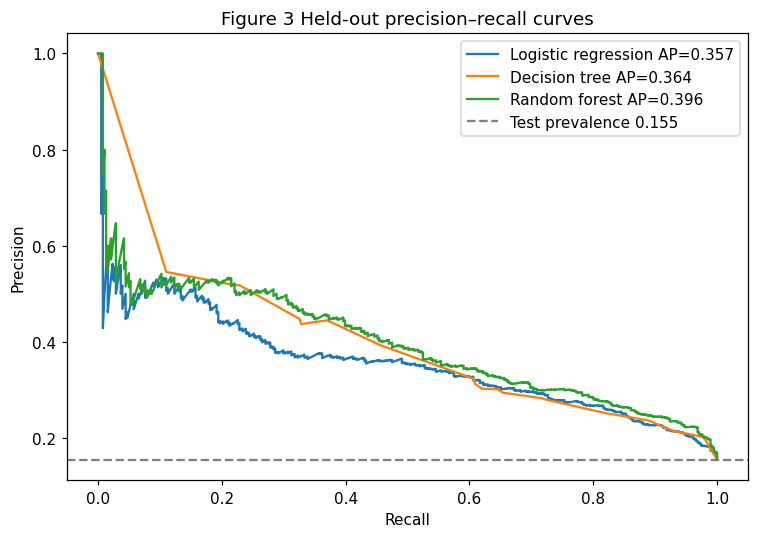

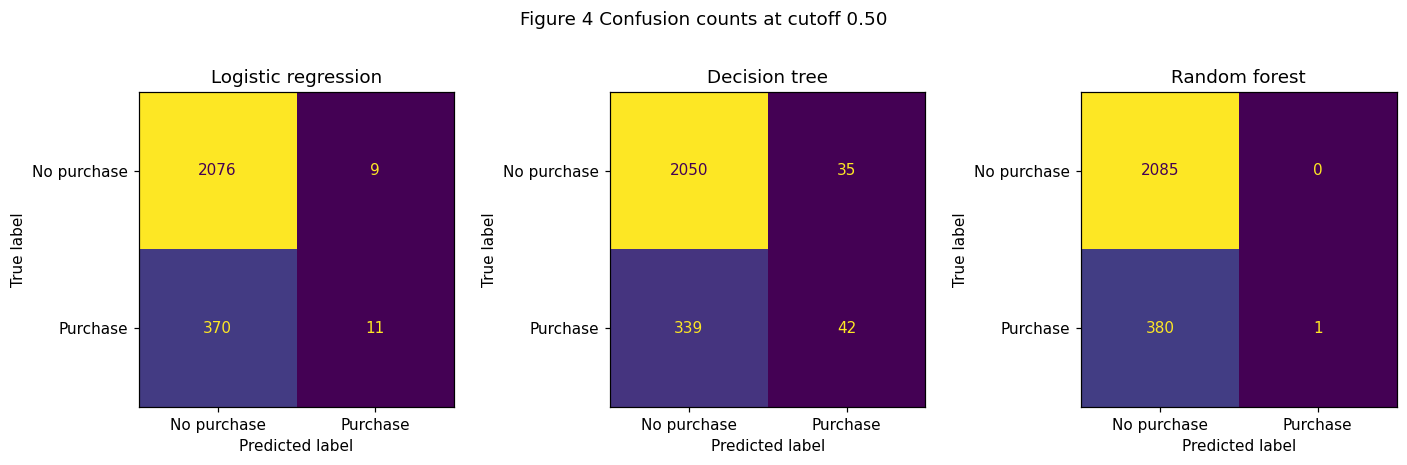

In [ ]:
def metrics(y, p):
    z = (p >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(y, z),
        "precision": precision_score(y, z, zero_division=0) if z.sum() else np.nan,
        "recall": recall_score(y, z, zero_division=0),
        "f1": f1_score(y, z, zero_division=0),
        "roc_auc": roc_auc_score(y, p),
        "average_precision": average_precision_score(y, p),
        "brier": brier_score_loss(y, p),
        "confusion_matrix": confusion_matrix(y, z).tolist(),
    }


results = []
predictions = {}
yt = test.Revenue.astype(int)
for key, s in searches.items():
    p = s.best_estimator_.predict_proba(test)[:, 1]
    predictions[key] = p
    results.append(
        {
            "scenario": key[0],
            "model": key[1],
            "cv_average_precision": s.best_score_,
            **metrics(yt, p),
        }
    )
p = np.full(len(test), dev.Revenue.mean())
results.append(
    {
        "scenario": "reference",
        "model": "constant development prevalence",
        **metrics(yt, p),
    }
)
model_results = pd.DataFrame(results)
display(model_results)

model_results.to_csv(OUT / "model_results.csv", index=False)
for key, search in searches.items():
    pd.DataFrame(search.cv_results_).to_csv(
        OUT / (key[0] + "_" + key[1].replace(" ", "_") + "_cv.csv"), index=False
    )
prediction_table = pd.DataFrame(
    {"source_row": test.index, "group_id": gtest, "actual": yt.to_numpy()}
)
for (scenario, name), probability in predictions.items():
    prediction_table[scenario + " | " + name] = probability
prediction_table.to_csv(OUT / "heldout_predictions.csv", index=False)

from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay

names = ["Logistic regression", "Decision tree", "Random forest"]
fig, ax = plt.subplots(figsize=(7, 5))
for name in names:
    pred = predictions[("primary", name)]
    precision, recall, _ = precision_recall_curve(yt, pred)
    ax.plot(recall, precision, label=f"{name} AP={average_precision_score(yt,pred):.3f}")
ax.axhline(
    yt.mean(), color="grey", linestyle="--", label=f"Test prevalence {yt.mean():.3f}"
)
ax.set(
    xlabel="Recall", ylabel="Precision", title="Figure 3 Held-out precision–recall curves"
)
ax.legend()
save_figure(fig, "figure_3_precision_recall.png")
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, names):
    matrix = confusion_matrix(yt, predictions[("primary", name)] >= 0.5)
    ConfusionMatrixDisplay(matrix, display_labels=["No purchase", "Purchase"]).plot(
        ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(name)
fig.suptitle("Figure 4 Confusion counts at cutoff 0.50", y=1.03)
save_figure(fig, "figure_4_confusion_counts.png")


### Interpreting the model comparison
Without PageValues, the forest achieves AP 0.396 and ROC-AUC 0.792. At 0.50, however, it detects only one purchaser and misses 380. Its precision of 1.0 is based on that single positive prediction. A perfect score from one attempt deserves a raised eyebrow and a look at recall.

The tree detects 42 purchasers and produces 35 false positives at the same cutoff. Its ranking score is lower than the forest's, but it identifies more purchasers under this particular decision rule. The appropriate choice depends on the action and the costs attached to each error.

With PageValues, the forest AP rises to 0.722. That gain makes the input's definition and availability at the intended prediction time central to interpretation. The historical record alone cannot validate early intervention.

## 8 Checking probabilities and interpreting model reliance
**Figure 5 asks whether the scores behave like probabilities.** Predictions are divided into five fixed bins. For each occupied bin, the code compares average predicted probability with the observed proportion of purchases. A point near the diagonal indicates agreement within that bin. Empty bins remain empty in the table. A model does not earn a certificate of excellence in a probability range it never used.

The bin means can conceal variation between individual sessions, and small bins are less stable. Brier score also reflects probability quality, but it combines several aspects of performance. These diagnostics support a cautious assessment of the scores (Scikit-learn developers, n.d.-c).

**Figure 6 asks which inputs the fitted forest relies on.** permutation_importance shuffles one original input, recalculates AP and records the decrease. It repeats this 20 times per input with seed 42. If shuffling a variable makes performance worse, the fitted model was using information associated with it. Whiskers show the population standard deviation across those 20 changes, as returned by the library (Scikit-learn developers, n.d.-d).

A large importance can reflect information shared with correlated inputs. Its size is specific to this model, holdout and score. A value of 0.0725 is a decrease in AP units, so it should not be read as a 7.25% improvement in sales.

**Code attribution.** The reliability-bin table is a project-specific grouping calculation. The variable-shuffle computation calls scikit-learn's permutation_importance directly. This distinction identifies who supplies each part of the calculation.

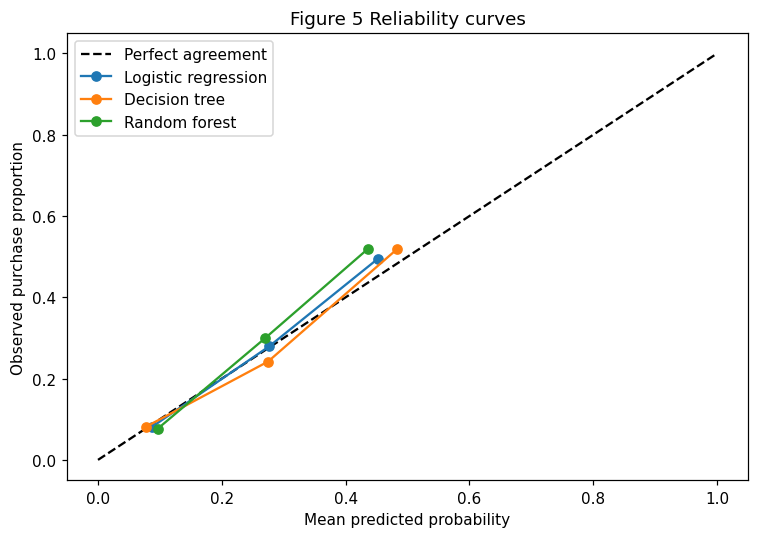

,model,bin,lower,upper,n,mean_probability,observed_proportion
0,Logistic regression,0,0.0,0.2,1673,0.087890,0.081889
1,Logistic regression,1,0.2,0.4,690,0.276793,0.279710
2,Logistic regression,2,0.4,0.6,103,0.452308,0.495146
3,Logistic regression,3,0.6,0.8,0,NaN,NaN
4,Logistic regression,4,0.8,1.0,0,NaN,NaN
5,Decision tree,0,0.0,0.2,1620,0.077491,0.081481
6,Decision tree,1,0.2,0.4,686,0.274730,0.241983
7,Decision tree,2,0.4,0.6,160,0.483176,0.518750
8,Decision tree,3,0.6,0.8,0,NaN,NaN
9,Decision tree,4,0.8,1.0,0,NaN,NaN


,variable,mean_drop_ap,sd_drop_ap
9,Month,0.072473,0.011176
5,ProductRelated_Duration,0.047613,0.012038
7,ExitRates,0.035950,0.012283
14,VisitorType,0.030408,0.005552
0,Administrative,0.023295,0.005673
1,Administrative_Duration,0.015564,0.004011
4,ProductRelated,0.011933,0.008904
6,BounceRates,0.007332,0.008625
10,OperatingSystems,0.005261,0.004031
13,TrafficType,0.003198,0.004464


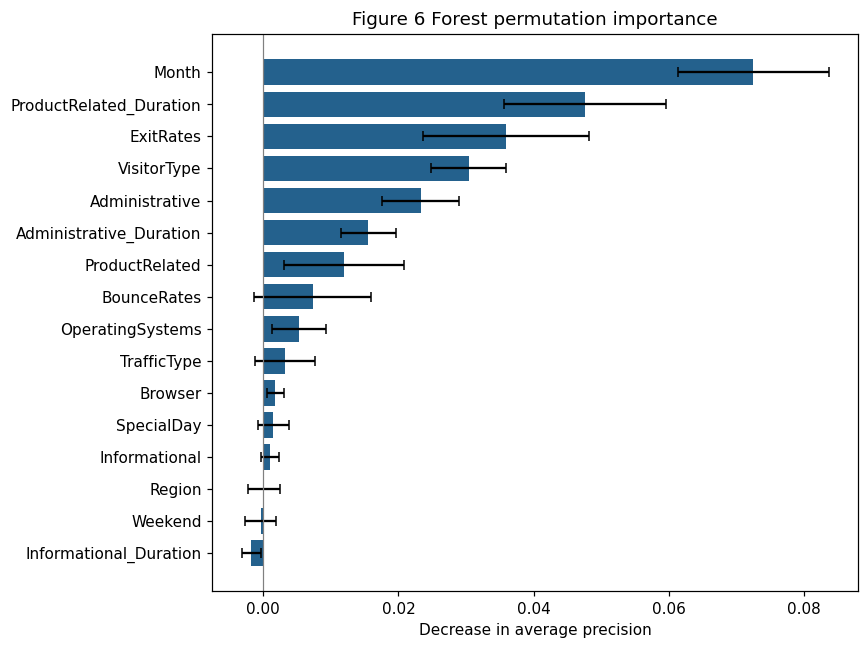

In [ ]:
calibration_rows = []
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 1], [0, 1], "--", color="black", label="Perfect agreement")
for name in names:
    pred = predictions[("primary", name)]
    bins = np.minimum((pred * 5).astype(int), 4)
    rows = []
    for b in range(5):
        mask = bins == b
        row = {
            "model": name,
            "bin": b,
            "lower": b / 5,
            "upper": (b + 1) / 5,
            "n": int(mask.sum()),
            "mean_probability": pred[mask].mean() if mask.any() else np.nan,
            "observed_proportion": yt.to_numpy()[mask].mean() if mask.any() else np.nan,
        }
        rows.append(row)
    table = pd.DataFrame(rows)
    calibration_rows.extend(rows)
    ax.plot(table.mean_probability, table.observed_proportion, marker="o", label=name)
ax.set(
    xlabel="Mean predicted probability",
    ylabel="Observed purchase proportion",
    title="Figure 5 Reliability curves",
)
ax.legend()
save_figure(fig, "figure_5_reliability.png")
calibration = pd.DataFrame(calibration_rows)
calibration.to_csv(OUT / "calibration_bins.csv", index=False)
display(calibration)

from sklearn.inspection import permutation_importance

forest = searches[("primary", "Random forest")].best_estimator_
base_ap = average_precision_score(yt, predictions[("primary", "Random forest")])
permuted = permutation_importance(
    forest,
    test[primary],
    yt,
    scoring="average_precision",
    n_repeats=20,
    random_state=SEED,
    n_jobs=1,
)
importance = pd.DataFrame(
    {
        "variable": primary,
        "mean_drop_ap": permuted.importances_mean,
        "sd_drop_ap": permuted.importances_std,
    }
).sort_values("mean_drop_ap", ascending=False)
importance.to_csv(OUT / "permutation_importance.csv", index=False)
display(importance)
plot = importance.sort_values("mean_drop_ap")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(
    plot.variable, plot.mean_drop_ap, xerr=plot.sd_drop_ap, color="#24618d", capsize=3
)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set(
    xlabel="Decrease in average precision", title="Figure 6 Forest permutation importance"
)
save_figure(fig, "figure_6_permutation_importance.png")


### Interpreting the diagnostic figures
Month has the largest mean permutation decrease, followed by product duration and exit rate. Month's prominence motivates checking whether a future dataset has comparable seasonal and traffic patterns. The current analysis cannot identify the mechanism behind that reliance.

In the forest's 0.40–0.60 bin, 52 sessions have mean predicted probability approximately 0.436 and observed purchase proportion approximately 0.519. This is a local diagnostic based on a small group. The two highest bins contain no sessions. Those blank spaces are information about coverage, even if they are less photogenic than another colourful line.

## 9 Checking uncertainty and repeated rows
A single holdout gives one set of results. The bootstrap asks how those evaluation results vary when the held-out groups are resampled with replacement.

The code builds 1,000 resampled collections of whole predictor-profile groups. Every model faces the same resampled records, which makes differences paired. The 2.5th and 97.5th percentiles provide a 95% percentile interval. Some groups appear more than once in a draw and others disappear. The spreadsheet is having a shuffle, rather than the model acquiring new shopping wisdom.

The fitted models remain fixed throughout this procedure. The resulting intervals describe conditional uncertainty in evaluating these fitted models. They omit the variation that would arise from fitting and tuning models on different development samples.

**The repeated-row sensitivity check.** Exact complete-row duplicates are removed separately within development and test. The model family is selected using development CV. Its chosen settings are locked, the model is refitted on deduplicated development records and it is assessed on the deduplicated test records.

**Code attribution.** The paired group-resampling loop and percentile reporting were assembled for this project using NumPy and pandas. The model refit uses scikit-learn's clone interface. The loop's grouping, fixed-model interpretation and pairing are methodological choices stated here. The resampling approach is related to the broader use of bootstrap methods discussed by James, et al. (2023, Chapter 5).

In [ ]:
# Paired group bootstrap, fixed fitted models
rng = np.random.default_rng(42)
test_group_indices = [np.flatnonzero(gtest == g) for g in np.unique(gtest)]
boot = []
for _ in range(1000):
    picked = rng.integers(0, len(test_group_indices), len(test_group_indices))
    ix = np.concatenate([test_group_indices[j] for j in picked])
    yy = yt.to_numpy()[ix]
    if len(np.unique(yy)) < 2:
        continue
    row = {}
    for key, pred in predictions.items():
        label = key[0] + " | " + key[1]
        row[label + " AP"] = average_precision_score(yy, pred[ix])
        row[label + " ROC AUC"] = roc_auc_score(yy, pred[ix])
    boot.append(row)
boot = pd.DataFrame(boot)
print("Valid bootstrap replicates:", len(boot))
display(boot.quantile([0.025, 0.5, 0.975]).T)
for name in ["Decision tree", "Random forest"]:
    delta = boot["primary | " + name + " AP"] - boot["primary | Logistic regression AP"]
    print(
        name, "minus logistic AP interval:", delta.quantile([0.025, 0.5, 0.975]).to_dict()
    )

boot.to_csv(OUT / "bootstrap_resamples.csv", index=False)
best_name = max(names, key=lambda name: searches[("primary", name)].best_score_)
unique_dev, unique_test = dev.drop_duplicates(), test.drop_duplicates()
refit = clone(searches[("primary", best_name)].best_estimator_).fit(
    unique_dev, unique_dev.Revenue.astype(int)
)
dedup_metrics = metrics(
    unique_test.Revenue.astype(int), refit.predict_proba(unique_test)[:, 1]
)
display(pd.Series(dedup_metrics, name="Deduplicated locked model"))
pd.DataFrame([{"model": best_name, **dedup_metrics}]).to_csv(
    OUT / "deduplicated_model_results.csv", index=False
)
association(df.drop_duplicates())[0].to_csv(
    OUT / "association_tests_deduplicated.csv", index=False
)


Valid bootstrap replicates: 1000


,0.025,0.500,0.975
primary | Logistic regression AP,0.312813,0.358844,0.405237
primary | Logistic regression ROC AUC,0.741800,0.765546,0.788061
primary | Decision tree AP,0.320660,0.365518,0.410705
primary | Decision tree ROC AUC,0.746336,0.771066,0.794206
primary | Random forest AP,0.348278,0.399462,0.448839
primary | Random forest ROC AUC,0.770072,0.791670,0.813278
with_PageValues | Logistic regression AP,0.579564,0.631908,0.681843
with_PageValues | Logistic regression ROC AUC,0.887088,0.903724,0.918197
with_PageValues | Decision tree AP,0.618478,0.666904,0.712521
with_PageValues | Decision tree ROC AUC,0.898122,0.912170,0.925896


Decision tree minus logistic AP interval: {0.025: -0.02883879561604194, 0.5: 0.007141273514092827, 0.975: 0.04076480823009619}
Random forest minus logistic AP interval: {0.025: 0.011402978400185703, 0.5: 0.03954957817608848, 0.975: 0.06834704231616177}


,Deduplicated locked model
accuracy,0.844198
precision,1.0
recall,0.002625
f1,0.005236
roc_auc,0.789298
average_precision,0.394612
brier,0.113653
confusion_matrix,"[[2058, 0], [380, 1]]"


### Interpreting the uncertainty check
The forest AP interval is approximately 0.348–0.449. The paired forest-minus-logistic AP interval is approximately 0.011–0.068. Both endpoints of the difference interval exceed zero in this run, supporting a conditional ranking advantage over the fitted logistic model on these resampled groups.

The deduplicated forest AP is approximately 0.395. This is close to the main result and leaves the weak purchaser detection at 0.50 visible. The check addresses sensitivity to exact repeated rows within this dataset. Broader validation still needs independent data.

## 10 Checking the notebook against the report
The reconciliation table compares calculated results with values transcribed from the report. It checks sample sizes, the 18 AP/ROC-AUC/Brier values across both scenarios, the forest's purchaser count, eight U statistics, 16 importance means and four bootstrap interval bounds.

The reference values are comparison targets. Model fitting and evaluation produce the calculated column before this comparison is made. The code never feeds the reference values into training. It is an answer check after doing the working.

**What True means here.** A match is assessed at the decimal precision printed in the report. It establishes numerical agreement for that checked value. It cannot independently establish representative sampling, causal explanation or benefit from a business intervention.

Your saved execution reports all 50 checks as matching. The code remains able to identify differences if another environment or input produces them.

**Code attribution.** This comparison is project-specific verification code. It uses Python rounding and pandas tabulation. The notebook's actual package versions are recorded separately, because software labels on an installation command cannot replace evidence of the environment that executed the analysis.

In [ ]:
checks = []


def check(label, actual, reference, decimals=3):
    checks.append(
        {
            "item": label,
            "calculated": float(actual),
            "report": float(reference),
            "matches": round(float(actual), decimals)
            == round(float(reference), decimals),
        }
    )


check("development_n", len(dev), 9864, 0)
check("test_n", len(test), 2466, 0)
check("test_purchases", yt.sum(), 381, 0)
references = {
    "primary": [(0.357, 0.766, 0.115), (0.364, 0.771, 0.113), (0.396, 0.792, 0.112)],
    "with_PageValues": [
        (0.630, 0.903, 0.122),
        (0.666, 0.912, 0.077),
        (0.722, 0.925, 0.078),
    ],
}
for scenario, rows in references.items():
    for name, values in zip(names, rows):
        result = model_results.query("scenario == @scenario and model == @name").iloc[0]
        for metric, reference in zip(["average_precision", "roc_auc", "brier"], values):
            check(f"{scenario} {name} {metric}", result[metric], reference)
check(
    "forest true positives",
    confusion_matrix(yt, predictions[("primary", "Random forest")] >= 0.5)[1, 1],
    1,
    0,
)
for variable, reference in zip(
    browse,
    [
        12464040.5,
        12398061.0,
        11236434.0,
        11173527.0,
        13093049.0,
        13382713.0,
        7686683.0,
        5903869.0,
    ],
):
    check(
        variable + " U",
        tests.set_index("variable").loc[variable, "statistic"],
        reference,
        1,
    )
importance_reference = {
    "Month": 0.0725,
    "ProductRelated_Duration": 0.0476,
    "ExitRates": 0.0359,
    "VisitorType": 0.0304,
    "Administrative": 0.0233,
    "Administrative_Duration": 0.0156,
    "ProductRelated": 0.0119,
    "BounceRates": 0.0073,
    "OperatingSystems": 0.0053,
    "TrafficType": 0.0032,
    "Browser": 0.0018,
    "SpecialDay": 0.0015,
    "Informational": 0.0010,
    "Region": 0.0001,
    "Weekend": -0.0004,
    "Informational_Duration": -0.0018,
}
for variable, reference in importance_reference.items():
    check(
        variable + " importance",
        importance.set_index("variable").loc[variable, "mean_drop_ap"],
        reference,
        4,
    )
delta = boot["primary | Random forest AP"] - boot["primary | Logistic regression AP"]
lo, hi = delta.quantile([0.025, 0.975])
check(
    "forest AP bootstrap lower", boot["primary | Random forest AP"].quantile(0.025), 0.348
)
check(
    "forest AP bootstrap upper", boot["primary | Random forest AP"].quantile(0.975), 0.449
)
check("paired AP difference lower", lo, 0.011)
check("paired AP difference upper", hi, 0.068)
comparison = pd.DataFrame(checks)
comparison.to_csv(OUT / "report_reconciliation.csv", index=False)
display(comparison)
print("All checked values reproduced:", comparison.matches.all())


,item,calculated,report,matches
0,development_n,9.864000e+03,9.864000e+03,True
1,test_n,2.466000e+03,2.466000e+03,True
2,test_purchases,3.810000e+02,3.810000e+02,True
3,primary Logistic regression average_precision,3.571563e-01,3.570000e-01,True
4,primary Logistic regression roc_auc,7.655583e-01,7.660000e-01,True
5,primary Logistic regression brier,1.149150e-01,1.150000e-01,True
6,primary Decision tree average_precision,3.639963e-01,3.640000e-01,True
7,primary Decision tree roc_auc,7.709240e-01,7.710000e-01,True
8,primary Decision tree brier,1.132949e-01,1.130000e-01,True
9,primary Random forest average_precision,3.964887e-01,3.960000e-01,True


All checked values reproduced: True


## 11 Answering the research questions
The next code cell generates a short interpretation directly from the computed tables and predictions. It also exports the environment metadata and a copy of the conclusions. This keeps the narrative tied to the numbers on the page.

**RQ1.** The distributions and superiority estimates describe how purchaser browsing differs. Longer product browsing and lower exit rates are useful patterns to investigate, with substantial overlap between the groups.

**RQ2.** The adjusted tests and effect sizes answer which selected measures are associated with the outcome. Rejection of H0 provides statistical evidence under the tests' assumptions. The research conclusion should retain the size and direction of the differences.

**RQ3.** Ranking scores and the error counts answer different parts of model usefulness. A strong place in the queue of likely purchasers does not guarantee that the model crosses its chosen decision cutoff.

**RQ4.** The recommendations follow from the observed limitations. Verify predictor timing, evaluate calibration, select a development-based cutoff using explicit business costs, and test the model on independent sessions. A controlled intervention study would be needed to estimate changes in sales.

**Code attribution.** The interpretation template and export steps are project-specific reporting code. They use the results already calculated above and retain the execution timestamp and software versions.

In [ ]:
tn, fp, fn, tp = confusion_matrix(
    yt, predictions[("primary", "Random forest")] >= 0.5
).ravel()
superiority = tests.set_index("variable").loc[
    "ProductRelated_Duration", "probability_purchase_greater_plus_half_ties"
]
pv_ap = average_precision_score(yt, predictions[("with_PageValues", "Random forest")])
conclusion = f"""### Computed findings
- **RQ1** Product-duration purchaser-first superiority is {superiority:.3f}. Values above 0.50 indicate a tendency towards larger purchaser values under the tie convention. Figure 2 shows the overlap.
- **RQ2** {int((tests.p_holm < .05).sum())} of nine null hypotheses are rejected after Holm adjustment. The test table shows each effect estimate and decision.
- **RQ3** The forest without PageValues achieves AP {base_ap:.3f}, against prevalence {yt.mean():.3f}. At 0.50 it detects {tp} purchasers, misses {fn}, and produces {fp} false positives. Its paired AP advantage over logistic regression has interval [{lo:.3f}, {hi:.3f}].
- **RQ4** Adding PageValues changes forest AP to {pv_ap:.3f}. Verify feature availability at the decision time, assess calibration and select a threshold on development data using explicit error costs. Independent temporal and retailer validation should assess transportability. Intervention trials would estimate effects on sales.

**Reconciliation:** {'All listed report checks match.' if comparison.matches.all() else 'Differences remain. Investigate failed checks before claiming exact report reproduction.'}
"""
display(Markdown(conclusion))
(OUT / "computed_conclusions.md").write_text(conclusion, encoding="utf-8")
metadata = {
    "executed_utc": datetime.now(timezone.utc).isoformat(),
    "versions": versions,
    "sha256": checksum,
    "seed": SEED,
    "group_method": "pandas.util.hash_pandas_object(index=False)",
    "all_report_checks_match": bool(comparison.matches.all()),
}
(OUT / "execution_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
print("Evidence saved to", OUT.resolve())


### Computed findings
- **RQ1** Product-duration purchaser-first superiority is 0.673. Values above 0.50 indicate a tendency towards larger purchaser values under the tie convention. Figure 2 shows the overlap.
- **RQ2** 9 of nine null hypotheses are rejected after Holm adjustment. The test table shows each effect estimate and decision.
- **RQ3** The forest without PageValues achieves AP 0.396, against prevalence 0.155. At 0.50 it detects 1 purchasers, misses 380, and produces 0 false positives. Its paired AP advantage over logistic regression has interval [0.011, 0.068].
- **RQ4** Adding PageValues changes forest AP to 0.722. Verify feature availability at the decision time, assess calibration and select a threshold on development data using explicit error costs. Independent temporal and retailer validation should assess transportability. Intervention trials would estimate effects on sales.

**Reconciliation:** All listed report checks match.


Evidence saved to /content/outputs


## References

Holm, S., 1979. A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6(2), pp.65–70. [online] Available at: https://www.jstor.org/stable/4615733 [Accessed 5 November 2026].

James, G., Witten, D., Hastie, T., Tibshirani, R. and Taylor, J., 2023. *An introduction to statistical learning with applications in Python*. Cham: Springer. Available at: https://doi.org/10.1007/978-3-031-38747-0 [Accessed 5 November 2026].

Matplotlib development team, n.d. *Matplotlib*. Version 3.10.8. [Computer program] Available at: https://matplotlib.org/3.10.8/ [Accessed 5 November 2026].

NumPy developers, n.d. *NumPy*. Version 2.4.6, recorded in the supplied execution. [Computer program] Available at: https://numpy.org/doc/2.4/ [Accessed 5 November 2026].

Patel, A., 2021. *Online Shoppers Purchasing Intention Dataset*. Version 1. [Dataset] Kaggle. Available at: https://www.kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset [Accessed 5 November 2026].

Saito, T. and Rehmsmeier, M., 2015. The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432. [online] Available at: https://doi.org/10.1371/journal.pone.0118432 [Accessed 5 November 2026].

Sakar, C. and Kastro, Y., 2018. *Online Shoppers Purchasing Intention Dataset*. [Dataset] UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5F88Q [Accessed 5 November 2026].

Scikit-learn developers, n.d.-a. *average_precision_score*. scikit-learn 1.8 documentation. [online] Available at: https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.average_precision_score.html [Accessed 5 November 2026].

Scikit-learn developers, n.d.-b. *GridSearchCV*. scikit-learn 1.8 documentation. [online] Available at: https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.GridSearchCV.html [Accessed 5 November 2026].

Scikit-learn developers, n.d.-c. *Metrics and scoring: quantifying the quality of predictions*. scikit-learn 1.8 documentation. [online] Available at: https://scikit-learn.org/1.8/modules/model_evaluation.html [Accessed 5 November 2026].

Scikit-learn developers, n.d.-d. *permutation_importance*. scikit-learn 1.8 documentation. [online] Available at: https://scikit-learn.org/1.8/modules/generated/sklearn.inspection.permutation_importance.html [Accessed 5 November 2026].

Scikit-learn developers, n.d.-e. *Pipeline*. scikit-learn 1.8 documentation. [online] Available at: https://scikit-learn.org/1.8/modules/generated/sklearn.pipeline.Pipeline.html [Accessed 5 November 2026].

Scikit-learn developers, n.d.-f. *scikit-learn*. Version 1.8.0. [Computer program] Available at: https://scikit-learn.org/1.8/ [Accessed 5 November 2026].

Scikit-learn developers, n.d.-g. *StratifiedGroupKFold*. scikit-learn 1.8 documentation. [online] Available at: https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html [Accessed 5 November 2026].

SciPy developers, n.d.-a. *chi2_contingency*. SciPy 1.17.0 documentation. [online] Available at: https://docs.scipy.org/doc/scipy-1.17.0/reference/generated/scipy.stats.chi2_contingency.html [Accessed 5 November 2026].

SciPy developers, n.d.-b. *mannwhitneyu*. SciPy 1.17.0 documentation. [online] Available at: https://docs.scipy.org/doc/scipy-1.17.0/reference/generated/scipy.stats.mannwhitneyu.html [Accessed 5 November 2026].

SciPy developers, n.d.-c. *SciPy*. Version 1.17.0. [Computer program] Available at: https://docs.scipy.org/doc/scipy-1.17.0/ [Accessed 5 November 2026].

The Independent Institute of Education, 2026. *Harvard – Anglia style reference guide adapted for The IIE*. [Institutional guide] pp.16–17, 45, 50–52. Guide supplied with the project and distributed through IIE Library. Available at: https://iielibraryconnect.iie.ac.za/e-shelf/referencing-and-plagiarism [Accessed 5 November 2026].

The pandas development team, n.d.-a. *pandas.util.hash_pandas_object*. pandas 2.2.3 documentation. [online] Available at: https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.util.hash_pandas_object.html [Accessed 5 November 2026].

The pandas development team, n.d.-b. *pandas*. Version 2.2.3. [Computer program] Available at: https://pandas.pydata.org/pandas-docs/version/2.2/ [Accessed 5 November 2026].